# Retail Sales Forecasting and Customer Analytics
## Customer Segmentation

### Purpose

The purpose of this analysis is to identify meaningful customer groups based on purchasing behaviour within the prepared retail dataset.

The exploratory analysis showed that approximately 97% of customers made only one delivered order and that customer spending is strongly right-skewed. Therefore, a segmentation method will not be selected automatically. Customer-level features will first be created and evaluated to determine whether they provide sufficient variation for meaningful segmentation.

The analysis will consider purchasing recency, frequency and monetary value, together with other relevant customer purchasing characteristics supported by the available data. Any transformations or modelling decisions will be justified using the observed data and later evaluated before the final customer segments are used in the Power BI dashboard.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Define project folders
project_path = Path.cwd().parent
cleaned_data_path = project_path / "02_Cleaned_Data"

# Load the prepared delivered transaction dataset
transactions = pd.read_csv(
    cleaned_data_path / "transactions_clean.csv"
)

print("Dataset shape:", transactions.shape)
transactions.head()

Dataset shape: (110197, 27)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,customer_state,geolocation_lat,geolocation_lng,sales_value,seller_city,seller_state,purchase_date,purchase_year,purchase_month,purchase_day_of_week
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,RJ,-21.763009,-41.310799,58.90,volta redonda,SP,2017-09-13,2017,2017-09,Wednesday
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,SP,-20.205187,-50.927017,239.90,sao paulo,SP,2017-04-26,2017,2017-04,Wednesday
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,MG,-19.870095,-44.593984,199.00,borda da mata,MG,2018-01-14,2018,2018-01,Sunday
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,SP,-23.106036,-46.592481,12.99,franca,SP,2018-08-08,2018,2018-08,Wednesday
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,SP,-23.245512,-46.825182,199.90,loanda,PR,2017-02-04,2017,2017-02,Saturday


In [2]:
# Convert the purchase timestamp to datetime

transactions["order_purchase_timestamp"] = pd.to_datetime(
    transactions["order_purchase_timestamp"],
    errors="coerce"
)

print("Missing purchase dates:",
      transactions["order_purchase_timestamp"].isna().sum())

print("Earliest purchase:",
      transactions["order_purchase_timestamp"].min())

print("Latest purchase:",
      transactions["order_purchase_timestamp"].max())

Missing purchase dates: 0
Earliest purchase: 2016-09-15 12:16:38
Latest purchase: 2018-08-29 15:00:37


In [3]:
# Set the reference date to one day after the latest purchase

reference_date = (
    transactions["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

print("Reference date:", reference_date)

Reference date: 2018-08-30 15:00:37


In [4]:
# Create customer-level purchasing features

customer_features = (
    transactions
    .groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        first_purchase=("order_purchase_timestamp", "min"),
        frequency=("order_id", "nunique"),
        monetary=("sales_value", "sum"),
        items_purchased=("order_item_id", "count"),
        average_item_value=("sales_value", "mean")
    )
    .reset_index()
)

# Calculate recency in days
customer_features["recency"] = (
    reference_date - customer_features["last_purchase"]
).dt.days

print("Number of customers:", len(customer_features))

customer_features[
    [
        "recency",
        "frequency",
        "monetary",
        "items_purchased",
        "average_item_value"
    ]
].describe()

Number of customers: 93358


,recency,frequency,monetary,items_purchased,average_item_value
count,93358.000000,93358.000000,93358.000000,93358.000000,93358.000000
mean,237.941773,1.033420,141.621480,1.180370,125.829535
std,152.591453,0.209097,215.694014,0.620857,190.533487
min,1.000000,1.000000,0.850000,1.000000,0.850000
25%,114.000000,1.000000,47.650000,1.000000,42.900000
50%,219.000000,1.000000,89.730000,1.000000,79.000000
75%,346.000000,1.000000,154.737500,1.000000,139.900000
max,714.000000,15.000000,13440.000000,24.000000,6735.000000


In [5]:
# Examine relationships between potential segmentation features

segmentation_features = customer_features[
    [
        "recency",
        "frequency",
        "monetary",
        "items_purchased",
        "average_item_value"
    ]
]

correlation_matrix = segmentation_features.corr()

correlation_matrix.round(3)

,recency,frequency,monetary,items_purchased,average_item_value
recency,1.000,-0.022,-0.000,-0.012,0.004
frequency,-0.022,1.000,0.106,0.437,-0.018
monetary,-0.000,0.106,1.000,0.190,0.918
items_purchased,-0.012,0.437,0.190,1.000,-0.058
average_item_value,0.004,-0.018,0.918,-0.058,1.000


### Evaluation of Customer Features

The customer-level features show different levels of variation and association. Purchase frequency has limited variation because most customers made only one delivered order. Items purchased provides slightly more variation, although it is moderately associated with purchase frequency (correlation = 0.437).

Monetary value and average item value have a very strong positive correlation (0.918). Including both variables in a clustering model could therefore give similar purchasing-value information excessive influence on the resulting segments. Recency, in contrast, has very weak correlations with the other features and represents a different aspect of customer behaviour.

These results indicate that all available customer features should not automatically be included in the segmentation model. Feature selection and transformation will be considered before clustering to reduce redundancy and account for the strongly skewed purchasing variables.

In [6]:
# Check skewness of potential segmentation features

features_to_check = [
    "recency",
    "frequency",
    "monetary",
    "items_purchased",
    "average_item_value"
]

skewness = (
    customer_features[features_to_check]
    .skew()
    .sort_values(ascending=False)
)

print("Feature Skewness")
print("----------------")
print(skewness.round(3))

Feature Skewness
----------------
frequency             11.095
monetary               9.747
average_item_value     7.829
items_purchased        7.443
recency                0.447
dtype: float64


In [7]:
# Test log transformation on the skewed customer features

customer_features["frequency_log"] = np.log1p(
    customer_features["frequency"]
)

customer_features["monetary_log"] = np.log1p(
    customer_features["monetary"]
)

customer_features["items_purchased_log"] = np.log1p(
    customer_features["items_purchased"]
)

customer_features["average_item_value_log"] = np.log1p(
    customer_features["average_item_value"]
)

transformed_skewness = customer_features[
    [
        "frequency_log",
        "monetary_log",
        "items_purchased_log",
        "average_item_value_log"
    ]
].skew()

print("Skewness After Log Transformation")
print("---------------------------------")
print(transformed_skewness.round(3))

Skewness After Log Transformation
---------------------------------
frequency_log             6.522
monetary_log              0.280
items_purchased_log       3.554
average_item_value_log    0.323
dtype: float64


In [8]:
# Examine the distribution of customer purchase frequency

frequency_distribution = (
    customer_features["frequency"]
    .value_counts()
    .sort_index()
    .reset_index()
)

frequency_distribution.columns = [
    "number_of_orders",
    "number_of_customers"
]

frequency_distribution["percentage_of_customers"] = (
    frequency_distribution["number_of_customers"]
    / len(customer_features)
    * 100
)

frequency_distribution.round(2)

,number_of_orders,number_of_customers,percentage_of_customers
0,1,90557,97.00
1,2,2573,2.76
2,3,181,0.19
3,4,28,0.03
4,5,9,0.01
5,6,5,0.01
6,7,3,0.00
7,9,1,0.00
8,15,1,0.00


### Purchase Frequency Assessment

Purchase frequency was examined in more detail because the initial feature analysis showed very limited variation. Of the 93,358 customers, 90,557 (97.0%) made only one delivered order. A further 2,573 customers (2.76%) made two orders, while fewer than 0.25% made three or more orders.

The log transformation reduced the skewness of monetary value and average item value substantially, but frequency remained strongly skewed. This is mainly caused by the underlying purchasing pattern rather than only by extreme values.

For this reason, frequency should not automatically be given equal importance in a distance-based clustering model. It will remain available as a descriptive customer characteristic, but the final clustering features will be selected based on their variation, redundancy and ability to represent distinct aspects of customer behaviour.

In [9]:
# Prepare candidate features for customer clustering

clustering_data = customer_features[
    ["customer_unique_id", "recency"]
].copy()

# Use transformed versions of the skewed purchasing variables
clustering_data["monetary_log"] = customer_features["monetary_log"]
clustering_data["items_purchased_log"] = customer_features["items_purchased_log"]

print("Clustering dataset shape:", clustering_data.shape)

print("\nMissing values:")
print(clustering_data.isnull().sum())

print("\nCandidate feature summary:")
print(
    clustering_data[
        ["recency", "monetary_log", "items_purchased_log"]
    ].describe().round(3)
)

Clustering dataset shape: (93358, 4)

Missing values:
customer_unique_id     0
recency                0
monetary_log           0
items_purchased_log    0
dtype: int64

Candidate feature summary:
         recency  monetary_log  items_purchased_log
count  93358.000     93358.000            93358.000
mean     237.942         4.486                0.757
std      152.591         0.923                0.187
min        1.000         0.615                0.693
25%      114.000         3.885                0.693
50%      219.000         4.508                0.693
75%      346.000         5.048                0.693
max      714.000         9.506                3.219


In [11]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ------ --------------------------------- 1.3/8.3 MB 6.7 MB/s eta 0:00:02
   ------------ --------------------------- 2.6/8.3 MB 6.9 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.3 MB 6.8 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.3 MB 6.8 MB/s eta 0:00:01
   ---------------------------------- ----- 7.1/8.3 MB 6.9 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.3 MB 6.9 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 6.4 MB/s eta 0:00:00
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Usin


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\trasc\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [12]:
# Standardise the candidate clustering features

from sklearn.preprocessing import StandardScaler

features_for_clustering = [
    "recency",
    "monetary_log",
    "items_purchased_log"
]

scaler = StandardScaler()

scaled_features = scaler.fit_transform(
    clustering_data[features_for_clustering]
)

scaled_features_df = pd.DataFrame(
    scaled_features,
    columns=features_for_clustering
)

print("Scaled feature summary:")
print(scaled_features_df.describe().round(3))

Scaled feature summary:
         recency  monetary_log  items_purchased_log
count  93358.000     93358.000            93358.000
mean      -0.000         0.000               -0.000
std        1.000         1.000                1.000
min       -1.553        -4.191               -0.341
25%       -0.812        -0.651               -0.341
50%       -0.124         0.024               -0.341
75%        0.708         0.609               -0.341
max        3.120         5.436               13.145


k = 2: inertia = 199381.49
k = 3: inertia = 141510.16
k = 4: inertia = 105775.67
k = 5: inertia = 91810.15
k = 6: inertia = 79180.24
k = 7: inertia = 69398.16
k = 8: inertia = 61196.04


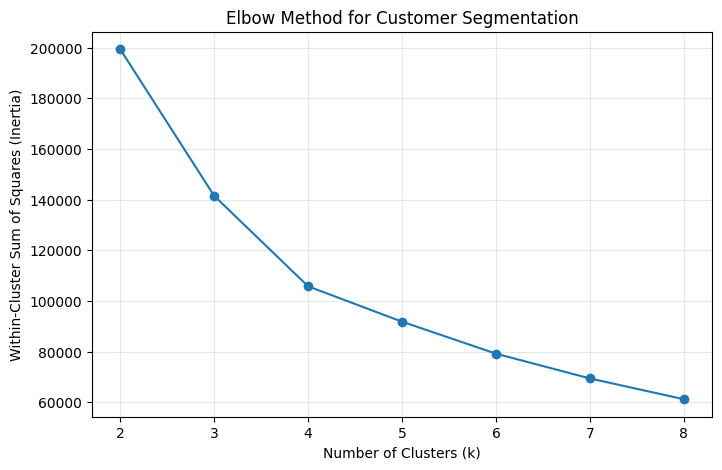

In [13]:
# Evaluate possible numbers of clusters using the Elbow Method

from sklearn.cluster import KMeans

inertia_values = []
k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(scaled_features_df)
    inertia_values.append(kmeans.inertia_)

# Display the values
for k, inertia in zip(k_values, inertia_values):
    print(f"k = {k}: inertia = {inertia:.2f}")

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")

plt.title("Elbow Method for Customer Segmentation")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.show()

In [14]:
# Evaluate cluster separation using silhouette scores

from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(scaled_features_df)

    score = silhouette_score(
        scaled_features_df,
        cluster_labels,
        sample_size=10000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"k = {k}: silhouette score = {score:.4f}")

k = 2: silhouette score = 0.4721
k = 3: silhouette score = 0.3421
k = 4: silhouette score = 0.3478
k = 5: silhouette score = 0.3286
k = 6: silhouette score = 0.3342
k = 7: silhouette score = 0.3268
k = 8: silhouette score = 0.3390


In [15]:
# Compare customer profiles for k=2 and k=4

for k in [2, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(scaled_features_df)

    comparison = customer_features[
        [
            "customer_unique_id",
            "recency",
            "frequency",
            "monetary",
            "items_purchased",
            "average_item_value"
        ]
    ].copy()

    comparison["cluster"] = labels

    profile = (
        comparison
        .groupby("cluster")
        .agg(
            customers=("customer_unique_id", "count"),
            avg_recency=("recency", "mean"),
            avg_frequency=("frequency", "mean"),
            avg_monetary=("monetary", "mean"),
            avg_items=("items_purchased", "mean")
        )
    )

    profile["customer_percentage"] = (
        profile["customers"] / len(comparison) * 100
    )

    print(f"\nK = {k}")
    print("-" * 60)
    print(profile.round(2))


K = 2
------------------------------------------------------------
         customers  avg_recency  avg_frequency  avg_monetary  avg_items  \
cluster                                                                   
0            11610       234.76           1.27        217.32       2.45   
1            81748       238.39           1.00        130.87       1.00   

         customer_percentage  
cluster                       
0                      12.44  
1                      87.56  

K = 4
------------------------------------------------------------
         customers  avg_recency  avg_frequency  avg_monetary  avg_items  \
cluster                                                                   
0            24548       428.52           1.00        102.44       1.01   
1            28795       152.46           1.00         43.46       1.00   
2            11323       229.85           1.27        221.78       2.46   
3            28692       163.87           1.00        242.03    

### Selection of the Number of Clusters

The number of clusters was evaluated using the elbow method, silhouette scores and the interpretability of the resulting customer profiles. The elbow curve showed substantial reductions in within-cluster variation up to approximately four clusters, after which the improvements became smaller.

The silhouette analysis produced the highest score for two clusters (0.4721), while the four-cluster solution produced a lower score of 0.3478. However, examination of the customer profiles showed that the two-cluster solution mainly separated customers according to whether they purchased approximately one item or multiple items. Although this solution provided stronger statistical separation, it offered limited detail for business analysis.

The four-cluster solution produced more distinct and interpretable purchasing profiles based on recency, monetary value and purchasing volume. These included customers with older purchases, recent lower-value customers, higher-value multi-item customers and recent higher-value customers.

Therefore, four clusters were selected as a practical balance between statistical evidence and business interpretability. The lower silhouette score compared with the two-cluster solution is recognised as a limitation and will be considered when evaluating the segmentation results.

In [16]:
# Fit the final K-Means model using four clusters

final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_features["cluster"] = final_kmeans.fit_predict(
    scaled_features_df
)

print("Customers assigned to clusters:")
print(customer_features["cluster"].value_counts().sort_index())

print("\nTotal customers:")
print(customer_features["cluster"].value_counts().sum())


Customers assigned to clusters:
cluster
0    24548
1    28795
2    11323
3    28692
Name: count, dtype: int64

Total customers:
93358


In [17]:
# Profile the final customer clusters using means and medians

cluster_profile = (
    customer_features
    .groupby("cluster")
    .agg(
        customers=("customer_unique_id", "count"),
        mean_recency=("recency", "mean"),
        median_recency=("recency", "median"),
        mean_frequency=("frequency", "mean"),
        median_frequency=("frequency", "median"),
        mean_monetary=("monetary", "mean"),
        median_monetary=("monetary", "median"),
        mean_items=("items_purchased", "mean"),
        median_items=("items_purchased", "median")
    )
)

cluster_profile["customer_percentage"] = (
    cluster_profile["customers"]
    / len(customer_features)
    * 100
)

cluster_profile.round(2)

,customers,mean_recency,median_recency,mean_frequency,median_frequency,mean_monetary,median_monetary,mean_items,median_items,customer_percentage
cluster,,,,,,,,,,
0,24548,428.52,421.0,1.00,1.0,102.44,77.00,1.01,1.0,26.29
1,28795,152.46,153.0,1.00,1.0,43.46,41.90,1.00,1.0,30.84
2,11323,229.85,212.0,1.27,1.0,221.78,149.70,2.46,2.0,12.13
3,28692,163.87,162.0,1.00,1.0,242.03,149.99,1.00,1.0,30.73


In [18]:
# Assign descriptive business names to the final clusters

segment_names = {
    0: "Older Purchase Customers",
    1: "Recent Lower-Value Customers",
    2: "Multi-Item Customers",
    3: "Recent Higher-Value Customers"
}

customer_features["segment"] = (
    customer_features["cluster"].map(segment_names)
)

segment_summary = (
    customer_features
    .groupby("segment")
    .agg(
        customers=("customer_unique_id", "count"),
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        median_items=("items_purchased", "median")
    )
    .sort_values("customers", ascending=False)
)

segment_summary["customer_percentage"] = (
    segment_summary["customers"]
    / len(customer_features)
    * 100
)

segment_summary.round(2)

,customers,median_recency,median_frequency,median_monetary,median_items,customer_percentage
segment,,,,,,
Recent Lower-Value Customers,28795,153.0,1.0,41.90,1.0,30.84
Recent Higher-Value Customers,28692,162.0,1.0,149.99,1.0,30.73
Older Purchase Customers,24548,421.0,1.0,77.00,1.0,26.29
Multi-Item Customers,11323,212.0,1.0,149.70,2.0,12.13


### Final Customer Segments

The final four-cluster model identified four customer groups with different purchasing characteristics.

**Recent Lower-Value Customers** represented 30.84% of customers. Their median recency was 153 days and their median product spend was 41.90. These customers purchased relatively recently compared with the older-purchase group but typically generated lower product values.

**Recent Higher-Value Customers** represented 30.73% of customers. Their median recency was 162 days and median product spend was 149.99. This group therefore combines relatively recent purchasing activity with higher product value.

**Older Purchase Customers** represented 26.29% of customers and had a median recency of 421 days. The name describes the observed timing of their purchases rather than assuming that these customers are inactive or lost.

**Multi-Item Customers** represented 12.13% of customers. Their median customer purchased two items and generated a median product value of 149.70. Although their median order frequency remained one, these customers typically purchased multiple items within their delivered order. Therefore, they should not be interpreted as repeat customers.

The segments describe patterns within the historical dataset rather than explaining the causes of customer behaviour. They can support comparison and filtering in the Power BI dashboard, but they should not be interpreted as evidence of customer loyalty, satisfaction or future behaviour.

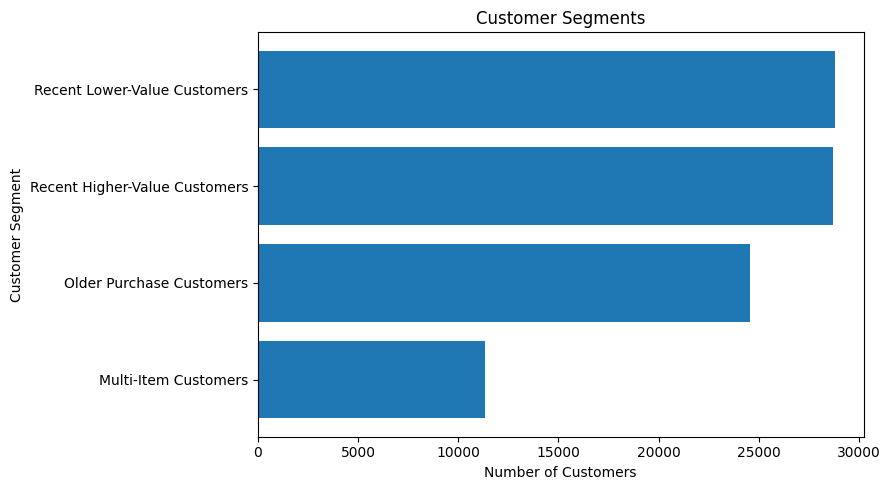

In [19]:
# Visualise the number of customers in each segment

segment_counts = (
    customer_features["segment"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 5))

plt.barh(
    segment_counts.index,
    segment_counts.values
)

plt.title("Customer Segments")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

In [20]:
# Export customer segmentation results for Power BI

segmentation_output = customer_features[
    [
        "customer_unique_id",
        "recency",
        "frequency",
        "monetary",
        "items_purchased",
        "average_item_value",
        "cluster",
        "segment"
    ]
].copy()

output_path = (
    cleaned_data_path / "customer_segments.csv"
)

segmentation_output.to_csv(
    output_path,
    index=False
)

print("File saved to:")
print(output_path)

print("\nExported shape:")
print(segmentation_output.shape)

print("\nMissing segment values:")
print(segmentation_output["segment"].isna().sum())

File saved to:
c:\Users\trasc\Desktop\Retail_Sales_Forecasting_Project\02_Cleaned_Data\customer_segments.csv

Exported shape:
(93358, 8)

Missing segment values:
0


In [21]:
# Validate the exported customer segmentation file

segments_check = pd.read_csv(
    cleaned_data_path / "customer_segments.csv"
)

print("Rows:", len(segments_check))
print("Unique customers:",
      segments_check["customer_unique_id"].nunique())

print("Duplicate customer IDs:",
      segments_check["customer_unique_id"].duplicated().sum())

print("Missing segments:",
      segments_check["segment"].isna().sum())

print("\nSegment counts:")
print(segments_check["segment"].value_counts())

Rows: 93358
Unique customers: 93358
Duplicate customer IDs: 0
Missing segments: 0

Segment counts:
segment
Recent Lower-Value Customers     28795
Recent Higher-Value Customers    28692
Older Purchase Customers         24548
Multi-Item Customers             11323
Name: count, dtype: int64


## Customer Segmentation Summary

Customer segmentation was developed using purchasing characteristics derived from the delivered transaction data. Initial analysis showed that traditional purchase frequency had limited discriminatory value because 97% of customers made only one delivered order. Monetary value and other purchasing variables were also strongly right-skewed, so log transformation and feature standardisation were considered before clustering.

The final K-Means model used recency, log-transformed monetary value and log-transformed items purchased. Average item value was excluded because it was strongly correlated with monetary value, while frequency was retained for customer profiling rather than used as a clustering feature because of its limited variation.

The number of clusters was evaluated using the elbow method, silhouette scores and business interpretability. Although two clusters produced the highest silhouette score of 0.4721, the four-cluster solution provided more useful behavioural differentiation. The four-cluster solution had a silhouette score of 0.3478, which is recognised as a limitation of the segmentation.

Four customer segments were identified: Recent Lower-Value Customers (30.84%), Recent Higher-Value Customers (30.73%), Older Purchase Customers (26.29%) and Multi-Item Customers (12.13%). The segment names describe observed purchasing characteristics and do not assume customer loyalty, satisfaction or future behaviour.

The final segmentation dataset contains 93,358 unique customers with no duplicate customer identifiers or missing segment assignments. It was exported as `customer_segments.csv` for integration into the Power BI dashboard.